<a href="https://colab.research.google.com/github/habibiputrar/DeepLearning_B_2411531001_Habibi-Putra-Rizqullah/blob/main/Praktikum7/2411531001_Habibi_Putra_Rizqullah_Program7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Deep Learning Minggu 7
Autoencoder untuk Representasi dan Rekonstruksi Citra

Nama : Habibi Putra Rizqullah  
NIM : 2411531001

## Tujuan
1. Membuat autoencoder dengan PyTorch untuk merekonstruksi citra MNIST.
2. Melihat pengaruh dimensi laten terhadap hasil rekonstruksi.
3. Mencoba denoising autoencoder dan membandingkannya dengan model tanpa noise.

In [ ]:
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
random.seed(42)
np.random.seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cpu


## Dataset

In [ ]:
transform = transforms.Compose([transforms.ToTensor()])

trainset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
testset = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

trainloader = torch.utils.data.DataLoader(trainset, batch_size=128, shuffle=True)
testloader = torch.utils.data.DataLoader(testset, batch_size=256, shuffle=False)

print(len(trainset), len(testset))

60000 10000


## Model

In [ ]:
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=3):
        super(Autoencoder, self).__init__()
        self.encoder = nn.Sequential(
            nn.Linear(28*28, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 12),
            nn.ReLU(),
            nn.Linear(12, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 12),
            nn.ReLU(),
            nn.Linear(12, 64),
            nn.ReLU(),
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, 28*28),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x


def add_noise(img, std):
    if std == 0:
        return img
    return torch.clamp(img + torch.randn_like(img) * std, 0, 1)

## Training
Untuk model dengan noise, input yang masuk ke model adalah citra yang sudah diberi noise, tetapi loss tetap dihitung terhadap citra asli.

In [ ]:
def train_model(latent_dim, noise_std, epochs=10):
    torch.manual_seed(42)
    model = Autoencoder(latent_dim).to(device)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    history = []

    for epoch in range(epochs):
        total, n = 0.0, 0
        for data, _ in trainloader:
            img = data.view(data.size(0), -1).to(device)
            output = model(add_noise(img, noise_std))
            loss = criterion(output, img)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item()
            n += 1
        history.append(total / n)
        print(f'Epoch [{epoch+1}/{epochs}], Loss: {history[-1]:.4f}')
    return model, history

### AE_1 (laten 3, tanpa noise)

In [ ]:
ae1, hist1 = train_model(latent_dim=3, noise_std=0)

Epoch [1/10], Loss: 0.0686


Epoch [2/10], Loss: 0.0506


Epoch [3/10], Loss: 0.0442


Epoch [4/10], Loss: 0.0415


Epoch [5/10], Loss: 0.0400


Epoch [6/10], Loss: 0.0389


Epoch [7/10], Loss: 0.0381


Epoch [8/10], Loss: 0.0375


Epoch [9/10], Loss: 0.0370


Epoch [10/10], Loss: 0.0366


loss AE_1 turun dari 0,0686 di epoch 1 menjadi 0,0366 di epoch 10. Penurunan paling besar terjadi pada tiga epoch pertama, setelah itu turunnya makin kecil.

### AE_2 (laten 3, noise Gaussian 0.1)

In [ ]:
ae2, hist2 = train_model(latent_dim=3, noise_std=0.1)

Epoch [1/10], Loss: 0.0691


Epoch [2/10], Loss: 0.0496


Epoch [3/10], Loss: 0.0440


Epoch [4/10], Loss: 0.0413


Epoch [5/10], Loss: 0.0396


Epoch [6/10], Loss: 0.0384


Epoch [7/10], Loss: 0.0376


Epoch [8/10], Loss: 0.0368


Epoch [9/10], Loss: 0.0363


Epoch [10/10], Loss: 0.0358


loss AE_2 turun dari 0,0691 menjadi 0,0358. Pola penurunannya hampir sama dengan AE_1 walaupun inputnya diberi noise.

### AE_3 (laten 2, tanpa noise)

In [ ]:
ae3, hist3 = train_model(latent_dim=2, noise_std=0)

Epoch [1/10], Loss: 0.0671


Epoch [2/10], Loss: 0.0523


Epoch [3/10], Loss: 0.0494


Epoch [4/10], Loss: 0.0468


Epoch [5/10], Loss: 0.0451


Epoch [6/10], Loss: 0.0439


Epoch [7/10], Loss: 0.0432


Epoch [8/10], Loss: 0.0426


Epoch [9/10], Loss: 0.0420


Epoch [10/10], Loss: 0.0415


loss AE_3 turun dari 0,0671 menjadi 0,0415. Nilai akhirnya paling tinggi di antara ketiga model, dan penurunannya juga lebih lambat.

## Analisis Hasil

### Loss per epoch

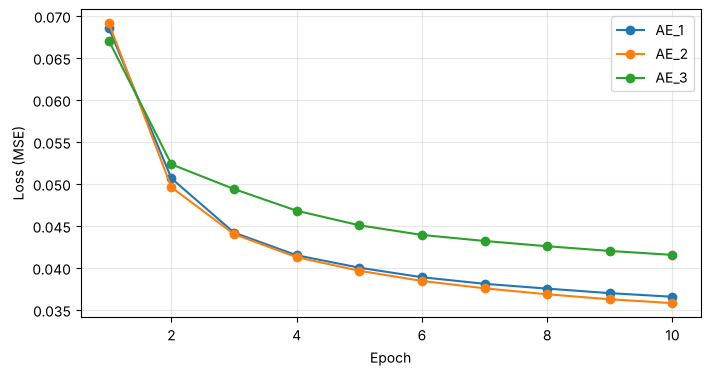

In [ ]:
epochs = range(1, 11)
plt.figure(figsize=(8, 4))
plt.plot(epochs, hist1, marker='o', label='AE_1')
plt.plot(epochs, hist2, marker='o', label='AE_2')
plt.plot(epochs, hist3, marker='o', label='AE_3')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

kurva AE_1 dan AE_2 hampir berimpit, sedangkan kurva AE_3 berada di atas keduanya sejak epoch 2 dan selisihnya tetap ada sampai epoch 10. Semua kurva sudah mulai landai di epoch 8 sampai 10, tetapi masih turun sedikit, jadi training lebih lama kemungkinan masih bisa menurunkan loss.

### Citra asli dan hasil rekonstruksi

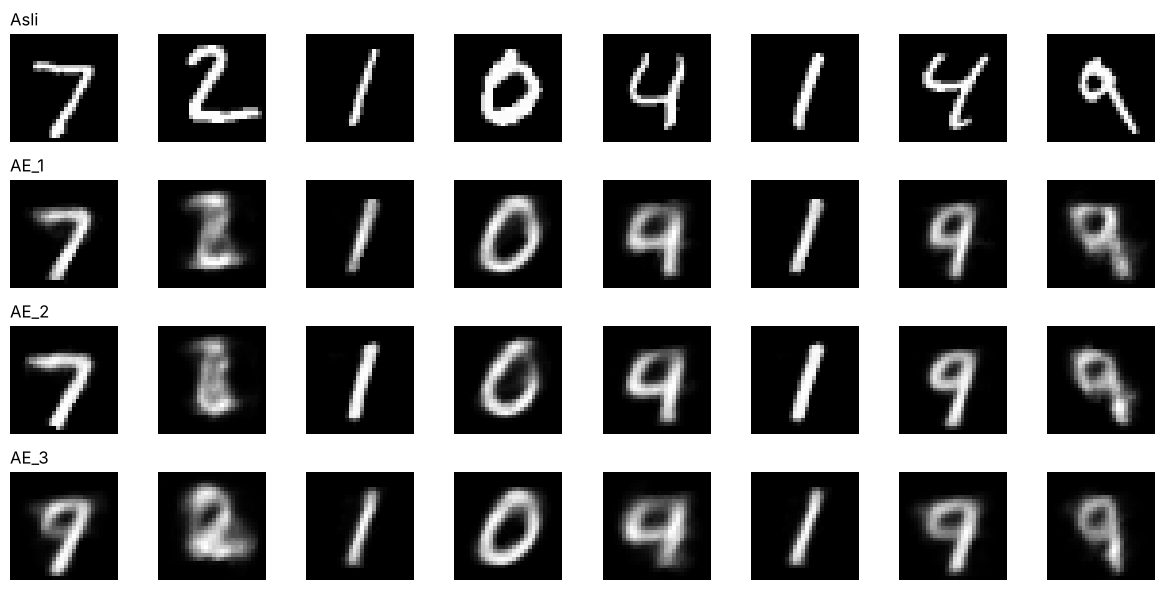

In [ ]:
def reconstruct(model, x):
    model.eval()
    with torch.no_grad():
        return model(x.to(device)).cpu()

images, labels = next(iter(testloader))
sample = images[:8].view(-1, 28*28)

rows = [('Asli', sample),
        ('AE_1', reconstruct(ae1, sample)),
        ('AE_2', reconstruct(ae2, sample)),
        ('AE_3', reconstruct(ae3, sample))]

fig, axes = plt.subplots(4, 8, figsize=(12, 6))
for r, (name, imgs) in enumerate(rows):
    for c in range(8):
        axes[r, c].imshow(imgs[c].view(28, 28), cmap='gray')
        axes[r, c].axis('off')
    axes[r, 0].set_title(name, loc='left')
plt.tight_layout()
plt.show()

baris pertama adalah citra asli, baris berikutnya hasil AE_1, AE_2, dan AE_3. Pada AE_1 dan AE_2, digit 7, 1, dan 0 sudah mirip aslinya. Digit 2 terlihat buram, dan kedua digit 4 berubah menjadi mirip 9. Pada AE_3, hasilnya lebih buram lagi: digit 7 berubah menjadi mirip 9 dan garis tipis pada digit 4 dan 9 menghilang. Jadi model dengan laten 3 masih bisa menangkap bentuk utama, sedangkan laten 2 mulai kehilangan banyak detail.

### Representasi laten AE_3

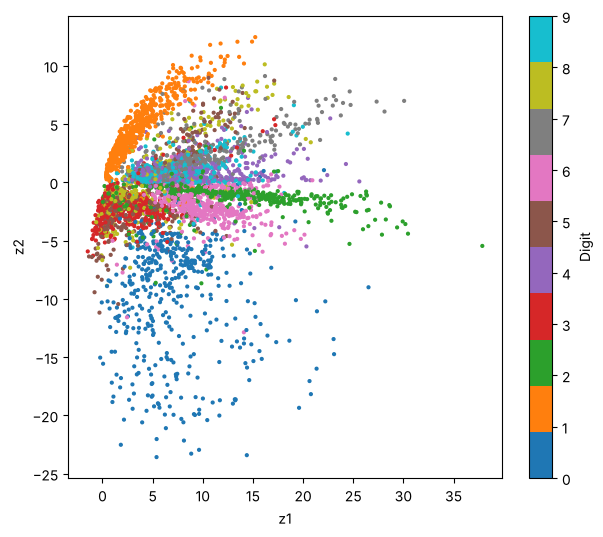

In [ ]:
ae3.eval()
zs, ys = [], []
with torch.no_grad():
    for data, y in testloader:
        zs.append(ae3.encoder(data.view(data.size(0), -1).to(device)).cpu())
        ys.append(y)
z = torch.cat(zs)[:5000]
y = torch.cat(ys)[:5000]

plt.figure(figsize=(7, 6))
plt.scatter(z[:, 0], z[:, 1], c=y, cmap='tab10', s=4)
plt.colorbar(label='Digit')
plt.xlabel('z1')
plt.ylabel('z2')
plt.show()

setiap titik adalah satu citra uji yang dipetakan ke dua angka laten. Digit 0 (biru) dan digit 1 (oranye) terkumpul di area yang terpisah. Digit lain, terutama 4, 7, dan 9, bertumpuk di tengah sehingga decoder sulit membedakannya. Hal ini sejalan dengan hasil rekonstruksi AE_3 yang sering salah pada digit-digit tersebut.

## Tugas Individu

### Denoising
Citra uji diberi noise Gaussian 0.1, lalu dimasukkan ke AE_1 (dilatih tanpa noise) dan AE_2 (dilatih dengan noise).

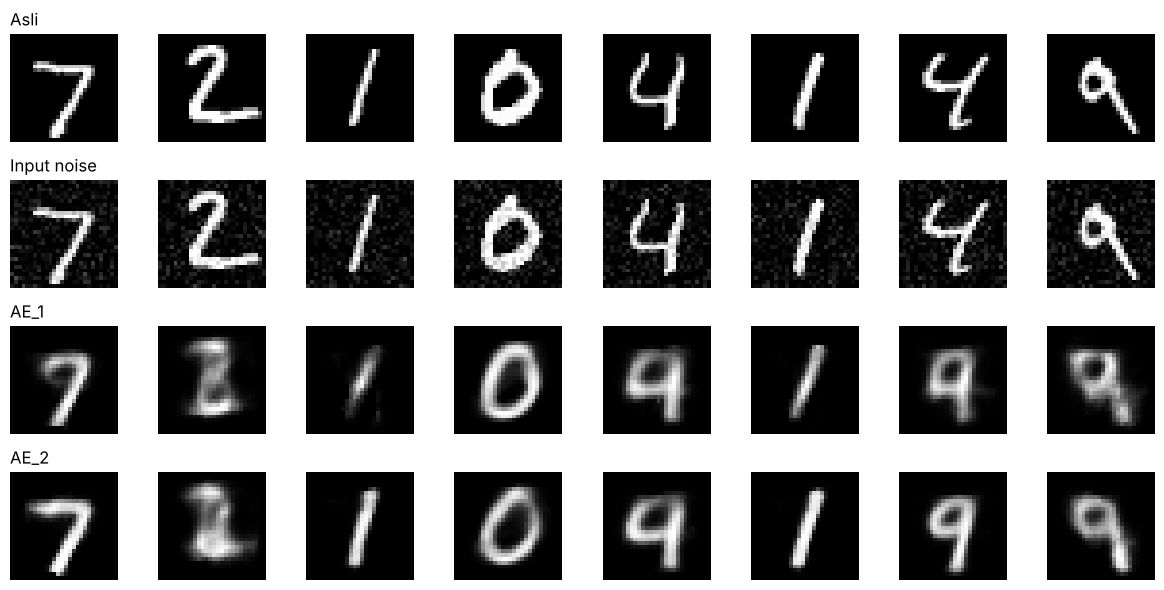

In [ ]:
torch.manual_seed(42)
noisy = add_noise(sample, 0.1)

rows = [('Asli', sample),
        ('Input noise', noisy),
        ('AE_1', reconstruct(ae1, noisy)),
        ('AE_2', reconstruct(ae2, noisy))]

fig, axes = plt.subplots(4, 8, figsize=(12, 6))
for r, (name, imgs) in enumerate(rows):
    for c in range(8):
        axes[r, c].imshow(imgs[c].view(28, 28), cmap='gray')
        axes[r, c].axis('off')
    axes[r, 0].set_title(name, loc='left')
plt.tight_layout()
plt.show()

baris kedua adalah citra uji yang sudah diberi noise Gaussian 0,1. AE_1 yang tidak pernah dilatih dengan noise menghasilkan rekonstruksi yang agak rusak, misalnya angka 1 di kolom ketiga hampir putus. AE_2 menghasilkan garis yang utuh pada digit yang sama, karena selama training ia terbiasa memetakan input bernoise ke citra bersih. Kesalahan pada digit 2 dan 4 masih muncul di kedua model, jadi noise bukan satu-satunya penyebab.

In [ ]:
def test_mse(model, noise_std):
    model.eval()
    torch.manual_seed(42)
    total, count = 0.0, 0
    with torch.no_grad():
        for data, _ in testloader:
            img = data.view(data.size(0), -1).to(device)
            out = model(add_noise(img, noise_std))
            total += ((out - img) ** 2).sum().item()
            count += img.numel()
    return total / count

print('AE_1 pada input noise 0.1:', round(test_mse(ae1, 0.1), 4))
print('AE_2 pada input noise 0.1:', round(test_mse(ae2, 0.1), 4))

AE_1 pada input noise 0.1: 0.0391


AE_2 pada input noise 0.1: 0.0357


pada input bernoise, MSE uji AE_1 sebesar 0,0391 dan AE_2 sebesar 0,0357. Nilai AE_2 lebih kecil, artinya rekonstruksinya lebih dekat ke citra bersih. Selisihnya tidak besar karena noise 0,1 termasuk ringan.

### Tabel hasil

In [ ]:
kualitas = {"AE_1": "Cukup baik", "AE_2": "Cukup baik", "AE_3": "Buram, detail hilang"}

hasil = pd.DataFrame({
    'Eksperimen': ['AE_1', 'AE_2', 'AE_3'],
    'Dimensi Laten': [3, 3, 2],
    'Noise': ['Tidak ada', 'Gaussian(0.1)', 'Tidak ada'],
    'Loss Akhir': [round(hist1[-1], 4), round(hist2[-1], 4), round(hist3[-1], 4)],
    'Kualitas Rekonstruksi': [kualitas['AE_1'], kualitas['AE_2'], kualitas['AE_3']]
})
hasil

,Eksperimen,Dimensi Laten,Noise,Loss Akhir,Kualitas Rekonstruksi
0,AE_1,3,Tidak ada,0.0366,Cukup baik
1,AE_2,3,Gaussian(0.1),0.0358,Cukup baik
2,AE_3,2,Tidak ada,0.0415,"Buram, detail hilang"


tabel merangkum ketiga eksperimen. AE_1 dan AE_2 memiliki loss akhir yang hampir sama (0,0366 dan 0,0358) dengan kualitas cukup baik, sedangkan AE_3 memiliki loss akhir tertinggi (0,0415) dan hasil yang buram. Kolom kualitas diisi berdasarkan perbandingan gambar rekonstruksi.

### Pembahasan
Loss ketiga model turun di setiap epoch dan mulai melandai pada epoch 8 sampai 10. Loss akhir AE_1 adalah 0,0366, AE_2 adalah 0,0358, dan AE_3 adalah 0,0415. Angka ini lebih besar dari contoh di tabel modul karena model hanya dilatih 10 epoch dengan bottleneck yang sangat kecil.

Pada AE_1, digit sederhana seperti 7, 1, dan 0 direkonstruksi cukup mirip dengan aslinya. Digit 2 terlihat buram, dan dua digit 4 pada contoh malah menjadi mirip 9. Tiga angka di lapisan laten belum cukup untuk membedakan 4 dan 9 yang bentuknya berdekatan.

Saat dimensi laten diturunkan menjadi 2 (AE_3), loss naik dari 0,0366 ke 0,0415 dan hasilnya makin buram. Digit 7 pada contoh berubah menjadi mirip 9, dan bagian tipis pada angka 4 dan 9 hilang. Plot ruang laten menunjukkan digit 0 dan 1 terpisah jelas, sedangkan digit 4, 7, dan 9 saling menumpuk sehingga decoder sering salah menebak di area itu.

Loss akhir AE_2 (0,0358) hampir sama dengan AE_1, selisihnya hanya 0,0008, jadi noise 0,1 hampir tidak mengubah loss training. Perbedaannya baru terlihat ketika kedua model diberi citra uji yang sudah bernoise. MSE uji AE_1 naik menjadi 0,0391, sedangkan AE_2 sebesar 0,0357. Pada gambar, angka 1 di kolom ketiga hampir putus pada keluaran AE_1, tetapi tetap utuh pada AE_2. AE_2 lebih tahan terhadap noise karena selama training ia dilatih mengembalikan citra bersih dari input yang terganggu.

### Kesimpulan
1. Dimensi laten yang lebih kecil menaikkan loss (0,0366 menjadi 0,0415) dan membuat rekonstruksi lebih buram, karena informasi yang bisa disimpan di bottleneck berkurang.
2. Noise Gaussian 0,1 hampir tidak mengubah loss training (0,0366 dan 0,0358), tetapi AE_2 lebih baik membersihkan input bernoise dengan MSE uji 0,0357 dibanding 0,0391 pada AE_1.
3. Dari tiga eksperimen, AE_1 dan AE_2 memberi rekonstruksi terbaik, sedangkan AE_3 paling buruk.

## Pertanyaan Reflektif
1. **Fungsi lapisan bottleneck.** Bottleneck adalah lapisan tersempit di tengah autoencoder. Lapisan ini memaksa 784 piksel dipadatkan menjadi 2 atau 3 angka, jadi model hanya menyimpan fitur yang paling penting dan tidak bisa sekadar menyalin input.
2. **Kenapa rekonstruksi tidak sama persis.** Sebagian informasi hilang saat dipadatkan di bottleneck, jadi decoder hanya menebak ulang gambar dari ringkasan yang ada. Hasil praktikum ini menunjukkan hal itu, misalnya digit 4 yang direkonstruksi menjadi mirip 9.
3. **Deteksi anomali.** Autoencoder dilatih hanya dengan data normal sehingga terbiasa merekonstruksi pola itu dengan error kecil. Data yang polanya berbeda akan menghasilkan error rekonstruksi yang besar, dan data dengan error di atas ambang tertentu dianggap anomali.